# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:**

- **Устройство:** свой ноутбук, NVIDIA GeForce RTX 3060 Laptop GPU (6 GB), Windows 10, Python 3.14, torch 2.11.0+cu128, transformers 5.22.1, datasets 5.1.0, accelerate 1.15.0, seqeval 1.2.2 (пины из `requirements_nlp.txt`). Финальный прогон: Restart & Run All с `FAST_MODE = False`, около 14 минут вместе с бонусами.
- **Модель:** [`cointegrated/rubert-tiny2`](https://huggingface.co/cointegrated/rubert-tiny2), ревизия `e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae`, лицензия MIT.
- **Датасет:** Collection3, [`RCC-MSU/collection3`](https://huggingface.co/datasets/RCC-MSU/collection3) (ветка `refs/convert/parquet`, коммит `2398327de1579acc44942636f27b8de1dcc69c1b`). Лицензия в карточке - `other` (не уточнена). Источник - labinform.ru (Persons-1000 + разметка LOC/ORG), IOB2 и сплиты от DeepPavlov. Использую в учебных целях.
- **Бонусы:** 6.2 ([`google-bert/bert-base-multilingual-cased`](https://huggingface.co/google-bert/bert-base-multilingual-cased), ревизия `3f076fdb1ab68d5b2880cb87a0886f315b8146f8`, Apache-2.0), 6.3, 6.4 (динамическая int8-квантизация на CPU и fp16 на GPU вместо ONNX), 6.5. Результаты бонусов лежат в `artifacts/bonus_metrics.json`.
- **Источники:** документация transformers (`Trainer`, `TrainingArguments`, token classification), datasets и seqeval, карточки модели и датасета. Код и тексты ответов подготовлены с помощью ИИ-ассистента (Claude Code).
- **Нерешенные задачи:** нет. Бонус 6.1 (доразметка) не выполнялся.

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

C:\Users\Руслан\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1122 13:25:14.223000 32940 torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


torch 2.11.0+cu128, transformers 5.22.1, datasets 5.1.0


CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda NVIDIA GeForce RTX 3060 Laptop GPU


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'cointegrated/rubert-tiny2'
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'
TOKENIZER_KWARGS = {}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}


BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:**

Взял `cointegrated/rubert-tiny2`. Это маленький русскоязычный BERT: 3 слоя, hidden 312, словарь 83 828 сабвордов, позиции до 2048. По карточке модель обучена так, чтобы ее эмбеддинги предложений приближали LaBSE, и ориентирована только на русский. Collection3 тоже русский, так что язык совпадает. Модель весит 112 MB (29.1M параметров), прямой проход батча 32×64 на RTX 3060 занимает 6.6 мс, а полное дообучение на 9.3k предложений - 41 с. Поэтому можно позволить себе подбор LR, абляцию и бонусы. По качеству на NER я ожидал заметно меньше, чем у base-моделей, но для новостных PER/LOC/ORG достаточно.

Альтернативы из списка:
- `DeepPavlov/rubert-base-cased`: ~180M параметров, 12 слоев × 768, тоже русская, качество выше, но обучение в разы дольше, а я хотел не сильно долго ждать обучение.
- `google-bert/bert-base-multilingual-cased`: ~178M, 104 языка, Apache-2.0. Словарь общий на все языки, поэтому русские слова режутся мельче (в 6.2 вышло 1.74 сабворда на слово против 1.14 у rubert-tiny2), а модель в 6 раз больше.

Без фиксации `revision` через полгода `main` может указывать на другой коммит. Владелец уже обновлял репозиторий (последнее изменение 2025-12-30). Если перезальют веса, токенизатор или конфиг, поменяются сабворды и метрики, ноутбук перестанет воспроизводиться. А если удалят файл весов или изменят формат конфига, загрузка просто упадет.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 3407.65it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    def n_params(params):
        return sum(p.numel() for p in params)

    base = model.base_model
    stack = base.encoder if hasattr(base, 'encoder') else base.transformer
    layer_params = [list(layer.parameters()) for layer in stack.layer]
    emb_params = list(base.embeddings.parameters())
    base_ids = {id(p) for p in base.parameters()}
    head_params = [p for p in model.parameters() if id(p) not in base_ids]

    used = {id(p) for p in emb_params} | {id(p) for ps in layer_params for p in ps} | {id(p) for p in head_params}
    other = [p for p in model.parameters() if id(p) not in used]
    layers = [n_params(ps) for ps in layer_params]
    return {'embeddings': n_params(emb_params), 'encoder': sum(layers), 'head': n_params(head_params),
            'other': n_params(other), 'layers': layers}

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)

for i, words in enumerate(demo_texts):
    print(f'{len(words)} слов -> {int(enc["attention_mask"][i].sum())} сабвордов:', enc.tokens(i))
    print('   word_ids:', enc.word_ids(i))
print()
for k, v in enc.items():
    print(f'{k:<17}{tuple(v.shape)}')
for i, h in enumerate(out.hidden_states):
    print(f'hidden_states[{i:>2}] {tuple(h.shape)}  <- {"выход эмбеддингов" if i == 0 else f"выход слоя {i}"}')
print(f'{"logits":<17}{tuple(out.logits.shape)}  <- голова: Linear({cfg.hidden_size}, {N_DEMO_LABELS}) на каждый сабворд')

6 слов -> 11 сабвордов: ['[CLS]', 'Петр', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке', '.', '[SEP]']
   word_ids: [None, 0, 1, 1, 2, 3, 4, 4, 4, 5, None]
6 слов -> 10 сабвордов: ['[CLS]', 'IT', '##M', '##O', 'University', 'is', 'in', 'Saint', 'Petersburg', '[SEP]', '[PAD]']
   word_ids: [None, 0, 0, 0, 1, 2, 3, 4, 5, None, None]

input_ids        (2, 11)
token_type_ids   (2, 11)
attention_mask   (2, 11)
hidden_states[ 0] (2, 11, 312)  <- выход эмбеддингов
hidden_states[ 1] (2, 11, 312)  <- выход слоя 1
hidden_states[ 2] (2, 11, 312)  <- выход слоя 2
hidden_states[ 3] (2, 11, 312)  <- выход слоя 3
logits           (2, 11, 7)  <- голова: Linear(312, 7) на каждый сабворд


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 6.6 ms на NVIDIA GeForce RTX 3060 Laptop GPU


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:**

Путь входа на `demo_texts`. Слова токенизатор режет на сабворды: «Чайковский» → `Чайк ##овский`, «Воткинске» → `Вот ##кинс ##ке`, «ITMO» → `IT ##M ##O`. Добавляются `[CLS]`/`[SEP]`, и батч дополняется `[PAD]` до самого длинного предложения. Получаются `input_ids`, `token_type_ids`, `attention_mask` формы (2, 11). Эмбеддинги дают `hidden_states[0]` формы (2, 11, 312), три слоя энкодера дают `hidden_states[1..3]`, каждый тоже (2, 11, 312), голова `Linear(312, 7)` выдает `logits` (2, 11, 7).

Больше всего параметров в эмбеддингах: 26.8M из 29.1M (92%). Причина в том, что таблица сабвордов 83 828 × 312 = 26.2M, к ней добавляются позиционные эмбеддинги 2048 × 312 = 0.64M. Слои при hidden 312 и FFN 600 маленькие, по 0.77M (все три слоя вместе 7.9%), голова - 2 191 параметр.

Токены обмениваются информацией только в слоях энкодера (self-attention). Эмбеддинги и голова token classification обрабатывают каждую позицию независимо.

`T` = 11 больше числа слов (6), потому что слова распадаются на несколько сабвордов, добавляются спецтокены и паддинг. Поэтому метки нужно выравнивать по `word_ids()` (2.2).

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID, DATASET_CONFIG = 'RCC-MSU/collection3', None
DATASET_REVISION = '2398327de1579acc44942636f27b8de1dcc69c1b'
raw = load_dataset(DATASET_ID, revision=DATASET_REVISION)
LABEL_NAMES = raw['train'].features['ner_tags'].feature.names
print(raw)
print(LABEL_NAMES)

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']


split        предл.    слов    LOC    ORG    PER  всего  предл. без сущн.


train          9301  187656   4881   5960   7406  18247       1815 (20%)
validation     2153   43856   1168   1308   1641   4117        504 (23%)
test           1922   40260   1175   1256   1570   4001        351 (18%)

длина спанов в словах (train), доли:
type        1      2      3      4     5+   mean  max
LOC     77.6%  15.6%   5.3%   0.6%   0.9%   1.32    8
ORG     53.8%  24.5%   9.6%   4.9%   7.1%   2.00   18
PER     27.4%  52.7%  16.7%   0.7%   2.5%   2.01   10

длина предложений в словах:


train       mean  20.2  median   18  p95   41  max 256
validation  mean  20.4  median   18  p95   41  max 118
test        mean  20.9  median   19  p95   42  max 122



доля сущностей validation, чья строка с тем же типом встречалась в train: LOC 81%, ORG 66%, PER 41% | всего 60%
LOC: 1183 разных строк на 4881 упоминаний; частые: РФ (492), России (333), США (250), Москвы (186), Белоруссии (80), Украины (74)
ORG: 2246 разных строк на 5960 упоминаний; частые: МВД (168), РИА Новости (128), СМИ (101), Единой России (86), ИА REGNUM (81), Госдумы (67)
PER: 4153 разных строк на 7406 упоминаний; частые: Дмитрий Медведев (106), Д . Медведев (72), Владимир Путин (59), Сергей Собянин (35), Обама (33), Медведев (33)


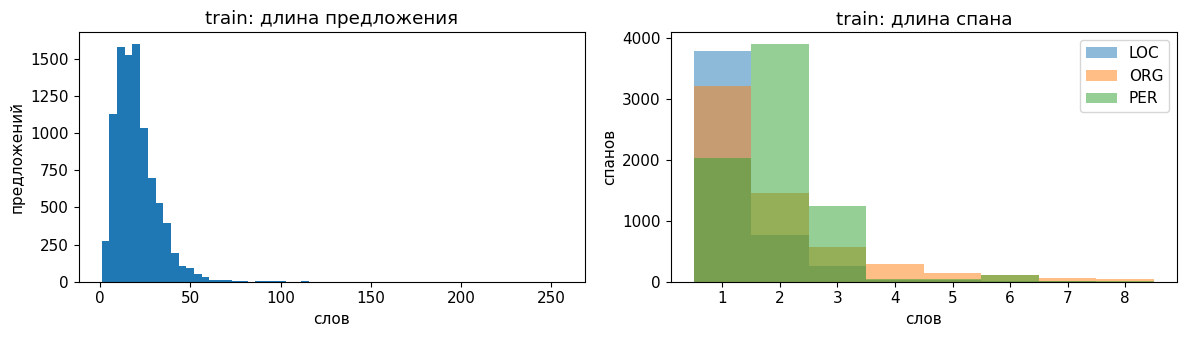

In [14]:
# ваша статистика: сущности по типам и сплитам, длины спанов в словах, длины предложений
from seqeval.metrics.sequence_labeling import get_entities

SPLITS = ['train', 'validation', 'test']


def entities_of(ds):
    out = []
    for k, tags in enumerate(ds['ner_tags']):
        for typ, s, e in get_entities([LABEL_NAMES[i] for i in tags]):
            out.append((k, s, e + 1, typ))
    return out


ents = {split: entities_of(raw[split]) for split in SPLITS}
TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})

print(f'{"split":<11}{"предл.":>8}{"слов":>8}' + ''.join(f'{t:>7}' for t in TYPES) + f'{"всего":>7}{"предл. без сущн.":>18}')
for split in SPLITS:
    ds = raw[split]
    cnt = collections.Counter(t for *_, t in ents[split])
    with_ent = len({k for k, *_ in ents[split]})
    print(f'{split:<11}{len(ds):>8}{sum(map(len, ds["tokens"])):>8}' + ''.join(f'{cnt[t]:>7}' for t in TYPES)
          + f'{len(ents[split]):>7}{len(ds) - with_ent:>11} ({1 - with_ent / len(ds):.0%})')

print('\nдлина спанов в словах (train), доли:')
print(f'{"type":<6}' + ''.join(f'{k:>7}' for k in ['1', '2', '3', '4', '5+']) + f'{"mean":>7}{"max":>5}')
for t in TYPES:
    lens = [e - s for _, s, e, typ in ents['train'] if typ == t]
    c = collections.Counter(min(n, 5) for n in lens)
    print(f'{t:<6}' + ''.join(f'{c[k] / len(lens):>7.1%}' for k in [1, 2, 3, 4, 5]) + f'{np.mean(lens):>7.2f}{max(lens):>5}')

print('\nдлина предложений в словах:')
for split in SPLITS:
    lens = np.array([len(ws) for ws in raw[split]['tokens']])
    print(f'{split:<11} mean {lens.mean():5.1f}  median {np.median(lens):4.0f}  p95 {np.percentile(lens, 95):4.0f}  max {lens.max()}')


train_tokens_all = [list(ws) for ws in raw['train']['tokens']]
val_tokens_all = [list(ws) for ws in raw['validation']['tokens']]
train_forms = [(' '.join(train_tokens_all[k][s:e]), t) for k, s, e, t in ents['train']]
val_forms = [(' '.join(val_tokens_all[k][s:e]), t) for k, s, e, t in ents['validation']]
train_form_set = set(train_forms)
seen = collections.Counter(t for f, t in val_forms if (f, t) in train_form_set)
total_t = collections.Counter(t for _, t in val_forms)
print('\nдоля сущностей validation, чья строка с тем же типом встречалась в train:',
      ', '.join(f'{t} {seen[t] / total_t[t]:.0%}' for t in TYPES), f'| всего {sum(seen.values()) / len(val_forms):.0%}')
for t in TYPES:
    forms_t = [f for f, tt in train_forms if tt == t]
    top = collections.Counter(forms_t).most_common(6)
    print(f'{t}: {len(set(forms_t))} разных строк на {len(forms_t)} упоминаний; частые:', ', '.join(f'{f} ({n})' for f, n in top))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist([len(ws) for ws in train_tokens_all], bins=60, color='tab:blue')
axes[0].set(title='train: длина предложения', xlabel='слов', ylabel='предложений')
for t in TYPES:
    lens = [e - s for _, s, e, typ in ents['train'] if typ == t]
    axes[1].hist(lens, bins=np.arange(0.5, 9.5), alpha=0.5, label=t)
axes[1].set(title='train: длина спана', xlabel='слов', ylabel='спанов')
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:**

**Collection3** ([HF](https://huggingface.co/datasets/RCC-MSU/collection3), parquet-ветка `refs/convert/parquet`, коммит `2398327d…`). Это 1000 новостных документов коллекции Persons-1000 (labinform.ru), в которых изначально были размечены только персоны. Метки LOC и ORG добавили вручную в Brat по правилам, близким к MUC-7, а в IOB2 со сплитами датасет перевела команда DeepPavlov. Разметка ручная. Лицензия в карточке - `other`, раздел Licensing Information не заполнен..

Типы и размеры:

| сплит | предл. | LOC | ORG | PER |
|---|---|---|---|---|
| train | 9301 | 4881 | 5960 | 7406 |
| validation | 2153 | 1168 | 1308 | 1641 |
| test | 1922 | 1175 | 1256 | 1570 |

По-настоящему редких типов нет, самый малочисленный LOC (~27% сущностей).

Особенности данных, которые могут повлиять на обучение:
- **LOC** почти всегда из одного слова (78%, в среднем 1.32 слова) и сильно повторяется: на 4881 упоминание 1183 разных строки, в топе РФ, России, США. 81% LOC из validation встречались в train с тем же типом.
- **ORG** длинные (в среднем 2.0 слова, 7% длиннее 4 слов, максимум 18) и разнообразные (2246 разных строк), в train встречались 66%.
- **PER** обычно из двух слов (53%), часто с инициалом через отдельный токен-точку («Д . Медведев»). Из validation в train встречались только 41%, поэтому словарный подход для PER слаб, а модели нужно обобщать по форме слова и контексту.
- **Предложения** в среднем по 20 слов (p95 41, максимум 256 в train), 18-23% предложений вообще без сущностей.
- **Шум разметки:** 5 предложений в train и 1 в test с `I-X` без `B-X`. Есть спорные решения, например «Кремль» как LOC и «Московский военный округ» как LOC. Вложенных сущностей формат не допускает.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans, start, cur = [], None, None
    for i, tag in enumerate(tags):
        if tag == 'O':
            prefix, typ = 'O', None
        elif tag[:2] in ('B-', 'I-'):
            prefix, typ = tag[0], tag[2:]
        else:
            raise ValueError(f'не BIO-тег: {tag!r}')
        if cur is not None and (prefix != 'I' or typ != cur):
            spans.append((start, i, cur))
            cur = None
        if prefix != 'O' and cur is None:
            start, cur = i, typ
    if cur is not None:
        spans.append((start, len(tags), cur))
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ['O'] * n_words
    for start, end, typ in sorted(spans):
        if not 0 <= start < end <= n_words:
            raise ValueError(f'спан {(start, end, typ)} вне [0, {n_words})')
        if any(t != 'O' for t in tags[start:end]):
            raise ValueError(f'спан {(start, end, typ)} пересекается с другим - в BIO его не записать')
        tags[start] = 'B-' + typ
        tags[start + 1:end] = ['I-' + typ] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    labels, prev = [], None
    for w in word_ids:
        if w is None:
            labels.append(-100)
        elif w != prev:
            labels.append(word_labels[w])
        elif b_to_i is None:
            labels.append(-100)
        else:
            labels.append(b_to_i.get(word_labels[w], word_labels[w]))
        prev = w
    return labels

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
# если датасет не в формате «слова + BIO»: конвертация в контракт из 2.1
# если уже в BIO: экспорт в спаны JSON (data/<split>_spans.jsonl), чтение обратно, BIO, сравнение с исходным
from datasets import Dataset

DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
tag2id = {t: i for i, t in enumerate(LABEL_NAMES)}


def export_spans(ds, path):
    with path.open('w', encoding='utf-8') as f:
        for ex in ds:
            spans = bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
            f.write(json.dumps({'id': ex['id'], 'tokens': ex['tokens'], 'spans': [[s, e, t] for s, e, t in spans]},
                               ensure_ascii=False) + '\n')


def read_spans(path):
    with path.open(encoding='utf-8') as f:
        return [json.loads(line) for line in f]


converted, mismatched = {}, {}
for split in SPLITS:
    path = DATA_DIR / f'{split}_spans.jsonl'
    export_spans(raw[split], path)
    records = read_spans(path)
    assert len(records) == len(raw[split])
    rows, bad = [], []
    for rec, ex in zip(records, raw[split]):
        assert rec['id'] == ex['id'] and rec['tokens'] == ex['tokens']
        spans = [tuple(s) for s in rec['spans']]
        back = spans_to_bio(spans, len(rec['tokens']))
        orig = [LABEL_NAMES[i] for i in ex['ner_tags']]
        assert bio_to_spans(back) == bio_to_spans(orig) == spans
        if back != orig:
            bad.append((rec, orig, back))
        rows.append({'id': rec['id'], 'tokens': rec['tokens'], 'ner_tags': [tag2id[t] for t in back]})
    converted[split], mismatched[split] = Dataset.from_list(rows, features=raw[split].features), bad
    print(f'{split:<11}{len(records):>6} предложений, {sum(len(r["spans"]) for r in records):>6} спанов, '
          f'{path.stat().st_size / 2**10:5.0f} KB | BIO совпал дословно: {len(records) - len(bad)}, '
          f'отличается только I-X без B-X -> B-X: {len(bad)}')

for split in SPLITS:
    for rec, orig, back in mismatched[split]:
        diff = [(i, rec['tokens'][i], o, b) for i, (o, b) in enumerate(zip(orig, back)) if o != b]
        print(f'  {split} id={rec["id"]}: ' + '; '.join(f'«{w}» {o} -> {b}' for _, w, o, b in diff))

weird = [(split, w) for split in SPLITS for ws in raw[split]['tokens'] for w in ws if not w.strip() or any(c.isspace() for c in w)]
print('слов, пустых или с пробелами внутри:', len(weird), weird[:5])

raw = DatasetDict(converted)

rec = read_spans(DATA_DIR / 'train_spans.jsonl')[1]
print('\nпример:', ' '.join(rec['tokens']))
for s, e, t in rec['spans']:
    print(f'  [{s}, {e}) {t:<4} {" ".join(rec["tokens"][s:e])}')

train        9301 предложений,  18247 спанов,  3315 KB | BIO совпал дословно: 9296, отличается только I-X без B-X -> B-X: 5


validation   2153 предложений,   4117 спанов,   769 KB | BIO совпал дословно: 2153, отличается только I-X без B-X -> B-X: 0


test         1922 предложений,   4001 спанов,   706 KB | BIO совпал дословно: 1921, отличается только I-X без B-X -> B-X: 1
  train id=1751: «о» I-PER -> B-PER
  train id=2524: «Власть» I-ORG -> B-ORG
  train id=3143: «Ответственность» I-ORG -> B-ORG
  train id=3144: «Процветание» I-ORG -> B-ORG
  train id=7335: «Северный» I-ORG -> B-ORG
  test id=1242: «Первоуральск» I-ORG -> B-ORG


слов, пустых или с пробелами внутри: 0 []

пример: Президент России Дмитрий Медведев присвоил звания сотрудников полиции и переназначил 14 руководителей управлений , главных управлений и министерств внутренних дел по субъектам РФ и федеральным округам .
  [1, 2) LOC  России
  [2, 4) PER  Дмитрий Медведев
  [22, 23) LOC  РФ


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/9301 [00:00<?, ? examples/s]

Map:  22%|██▏       | 2000/9301 [00:00<00:00, 15206.86 examples/s]

Map:  43%|████▎     | 4000/9301 [00:00<00:00, 15521.86 examples/s]

Map:  65%|██████▍   | 6000/9301 [00:00<00:00, 14107.52 examples/s]

Map:  86%|████████▌ | 8000/9301 [00:00<00:00, 11900.26 examples/s]

Map: 100%|██████████| 9301/9301 [00:00<00:00, 12953.18 examples/s]

... (4 outputs left out)

Map: 100%|██████████| 1922/1922 [00:00<00:00, 14940.68 examples/s]

Map: 100%|██████████| 1922/1922 [00:00<00:00, 14513.42 examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
ENTITY_TYPES ['LOC', 'ORG', 'PER']


train: проверено 9288 предложений, обрезано по MAX_LENGTH 10, слов без сабвордов или за обрезкой 434
[CLS]            None  -100
До                  0  O
##полнение          0  -100
:                   1  O
Д                   2  B-PER
.                   3  I-PER
Медведев            4  I-PER
присвоил            5  O
звания              6  O
сотрудников         7  O
полиции             8  O
и                   9  O
перена             10  O
##зна              10  -100
##чил              10  -100
14                 11  O
руководителей      12  O
УВД                13  B-ORG
,                  14  O
ГУВД               15  B-ORG
и                  16  O
МВД                17  B-ORG
по                 18  O
субъектам          19  O
РФ                 20  B-LOC
.                  21  O
[SEP]            None  -100


In [19]:
for split in SPLITS:
    no_sub, cut_words, cut_sents, cut_ents = collections.Counter(), 0, 0, 0
    for ex in data[split]:
        full_ids = set(tokenizer(ex['tokens'], is_split_into_words=True).word_ids()) - {None}
        kept_ids = set(tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH).word_ids()) - {None}
        no_sub.update(ex['tokens'][w] for w in range(len(ex['tokens'])) if w not in full_ids)
        cut = full_ids - kept_ids
        cut_words += len(cut)
        cut_sents += bool(cut)
        cut_ents += sum(1 for s, e, t in bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']]) if s in cut)
    print(f'{split:<11} обрезано предложений {cut_sents}, слов за обрезкой {cut_words}, сущностей за обрезкой {cut_ents}; '
          f'слов без сабвордов {sum(no_sub.values())}: {[(repr(w), n) for w, n in no_sub.most_common(5)]}')

train       обрезано предложений 10, слов за обрезкой 430, сущностей за обрезкой 57; слов без сабвордов 4: [("'\\xad'", 4)]


validation  обрезано предложений 1, слов за обрезкой 7, сущностей за обрезкой 3; слов без сабвордов 0: []


test        обрезано предложений 1, слов за обрезкой 15, сущностей за обрезкой 0; слов без сабвордов 1: [("'\\xad'", 1)]


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:**

Метка ставится только на первый сабворд, потому что разметка и оценка идут по словам: тег слова - это предсказание на его первом сабворде (`predict_word_tags`). Остальным сабвордам ставится -100. `CrossEntropyLoss` с `ignore_index=-100` исключает такие позиции и из суммы, и из знаменателя усреднения. В итоге каждое слово дает в loss ровно один вклад, независимо от того, на сколько сабвордов оно режется, и не нужно придумывать тег для продолжения слова.

Обрезка по `MAX_LENGTH = 128` и слова без сабвордов:

| сплит | обрезано предл. | слов за обрезкой | сущностей за обрезкой | слов без сабвордов |
|---|---|---|---|---|
| train | 10 | 430 | 57 | 4 |
| validation | 1 | 7 | 3 | 0 |
| test | 1 | 15 | 0 | 1 |

Без сабвордов остаются только токены из одного мягкого переноса `\xad`. Все такие слова получают `O`. На validation это гарантированно 3 пропущенные сущности из 4117 (<0.1% recall), на метрику почти не влияет. В train 57 сущностей просто не участвуют в обучении.

Как прошла конвертация: BIO → спаны → `data/<split>_spans.jsonl` → BIO совпало дословно у 9296/9301 предложений train, 2153/2153 validation и 1921/1922 test. Спаны совпали везде. Расхождения - это 6 предложений с `I-X` без `B-X` («Северный» I-ORG, «Первоуральск» I-ORG и т.п.): после конвертации они стали `B-X`, ровно так, как их читает seqeval. Дальше обучение идет на этой нормализованной разметке. Пересекающихся или вложенных спанов, а также пустых токенов и токенов с пробелами нет: `spans_to_bio` упал бы на пересечении.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [20]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [21]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        assert len(words) == len(tags)
        for w, t in zip(words, tags):
            counts[w][t] += 1
    return {w: c.most_common(1)[0][0] for w, c in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(w, 'O') for w in words]

In [22]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

baseline = {}   # ваш код: baseline['majority'] и baseline['random_head'] - словари entity_scores

In [23]:
train_tokens = [list(ws) for ws in data['train']['tokens']]
train_tags = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
majority = fit_majority_tagger(train_tokens, train_tags)
maj_pred = [predict_majority(majority, ws) for ws in val_tokens]
baseline['majority'] = entity_scores(val_gold, maj_pred)

set_seed(SEED)
random_model = make_model()
rand_pred = predict_word_tags(random_model, val_tokens)
baseline['random_head'] = entity_scores(val_gold, rand_pred)
del random_model

n_val_words = sum(map(len, val_tokens))
unk = sum(w not in majority for ws in val_tokens for w in ws)
print(f'словарь: {len(majority)} слов из train, незнакомых слов в validation {unk / n_val_words:.1%}')
for name, pred in [('majority', maj_pred), ('random_head', rand_pred)]:
    s = baseline[name]
    tag_share = collections.Counter(t for tags in pred for t in tags)
    print(f'{name:<12} F1 micro {s["f1_micro"]:.4f}  macro {s["f1_macro"]:.4f}  P {s["precision"]:.4f}  R {s["recall"]:.4f}'
          f' | предсказанные теги: ' + ', '.join(f'{t} {n / n_val_words:.0%}' for t, n in tag_share.most_common(4)))
print('gold теги: ' + ', '.join(f'{t} {n / n_val_words:.0%}' for t, n in collections.Counter(t for tags in val_gold for t in tags).most_common(4)))
print(classification_report(val_gold, maj_pred, digits=3, zero_division=0))

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 7518.96it/s]

словарь: 27410 слов из train, незнакомых слов в validation 11.2%
majority     F1 micro 0.5615  macro 0.5787  P 0.5629  R 0.5601 | предсказанные теги: O 89%, B-PER 3%, B-ORG 2%, B-LOC 2%
random_head  F1 micro 0.0381  macro 0.0353  P 0.0223  R 0.1304 | предсказанные теги: O 26%, I-PER 26%, B-PER 20%, I-LOC 11%
gold теги: O 83%, B-PER 4%, I-PER 4%, B-ORG 3%


              precision    recall  f1-score   support

         LOC      0.753     0.763     0.758      1168
         ORG      0.550     0.576     0.563      1308
         PER      0.428     0.403     0.415      1641

   micro avg      0.563     0.560     0.561      4117
   macro avg      0.577     0.581     0.579      4117
weighted avg      0.559     0.560     0.559      4117



**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:**

Словарный бейзлайн на validation:

| | F1 micro | P | R | LOC | ORG | PER |
|---|---|---|---|---|---|---|
| словарь | 0.562 | 0.563 | 0.560 | 0.758 | 0.563 | 0.415 |

Для бейзлайна без контекста это неплохо, потому что новости сильно повторяются: РФ, России, США, МВД. 81% LOC из validation встречались в train с тем же типом, поэтому LOC почти «выучены наизусть». Хуже всего с PER: только 41% имен встречались в train. Кроме того, у двухсловных имен каждое слово должно получить правильный B или I, а «Медведев» в train бывает и B-PER, и I-PER. Многие слова неоднозначны без контекста: «России» - это LOC, но внутри «Единой России» уже I-ORG. 11.2% слов validation в словаре нет, они получают `O`.

Энкодер со случайной головой дает F1 0.038 (P 0.022, R 0.130). Он предсказывает `O` только у 26% слов (в gold 83%), а `I-PER` у 26% и `B-PER` у 20%. Голова `Linear(312, 7)` инициализирована случайно и проецирует осмысленные признаки энкодера на произвольные направления тегов. Связь «признак → наш тег» появляется только при дообучении, поэтому argmax - по сути случайная функция токена. Получается масса коротких ложных спанов, а редкие попадания случайны. Предобученность энкодера здесь не помогает: он знает язык, но не знает, какой id у какого тега.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [24]:
from transformers.trainer_callback import PrinterCallback

LR = 5e-4
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4
TRAIN_PEAK_MEM_MB = {}


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    if freeze_encoder:
        base_ids = {id(p) for p in model.base_model.parameters()}
        for p in model.parameters():
            p.requires_grad = id(p) not in base_ids
    total_steps = math.ceil(len(train_ds) / batch_size) * epochs
    log_every = max(1, total_steps // 20)
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=2 * batch_size,
        warmup_steps=0.1, lr_scheduler_type='linear', weight_decay=0.01,
        eval_strategy='steps', eval_steps=log_every, logging_strategy='steps', logging_steps=log_every,
        save_strategy='no', report_to='none', fp16=torch.cuda.is_available(),
        seed=SEED, data_seed=SEED, dataloader_num_workers=0, disable_tqdm=True)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    trainer.remove_callback(PrinterCallback)
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    trainer.train()
    seconds = time.perf_counter() - start
    if torch.cuda.is_available():
        TRAIN_PEAK_MEM_MB[out_dir] = torch.cuda.max_memory_allocated() / 2**20
    history = [h for h in trainer.state.log_history if 'loss' in h or 'eval_loss' in h]
    return history, seconds

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 5304.94it/s]

обучение: 40.6 c на NVIDIA GeForce RTX 3060 Laptop GPU, 9301 предложений, 3 эпох(а)


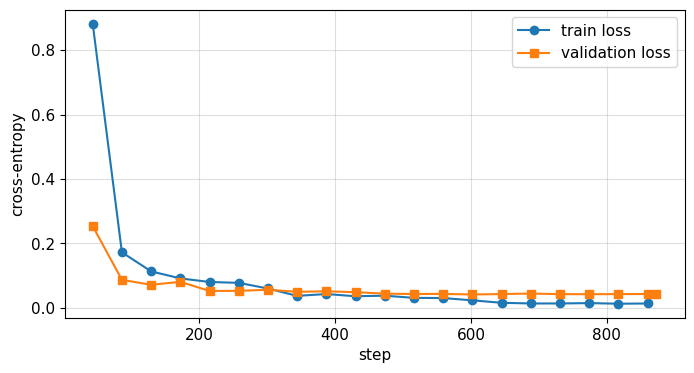

In [25]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

In [26]:
LR_GRID = [2e-4, 5e-4, 1e-3, 2e-3, 4e-3]
lr_search = {}
for lr in LR_GRID:
    if lr == LR:
        lr_hist, lr_sec, lr_model = history, train_seconds, model
    else:
        set_seed(SEED)
        lr_model = make_model()
        lr_hist, lr_sec = train_ner(lr_model, tokenized['train'], tokenized['validation'], lr=lr, out_dir=f'runs/lr_{lr:g}')
    ev = [h['eval_loss'] for h in lr_hist if 'eval_loss' in h]
    lr_search[lr] = dict(val_f1=entity_scores(val_gold, predict_word_tags(lr_model, val_tokens))['f1_micro'],
                         final_eval_loss=ev[-1], min_eval_loss=min(ev), train_sec=lr_sec)
    if lr_model is not model:
        del lr_model
        torch.cuda.empty_cache() if torch.cuda.is_available() else None
print(f'{"LR":>8}{"val F1":>9}{"eval loss":>11}{"min eval":>10}{"train, c":>10}')
for lr, r in lr_search.items():
    print(f'{lr:>8g}{r["val_f1"]:>9.4f}{r["final_eval_loss"]:>11.4f}{r["min_eval_loss"]:>10.4f}{r["train_sec"]:>10.1f}'
          + ('  <- LR основного прогона' if lr == LR else ''))
RUN_TIMES['lr_search'] = lr_search

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 5063.05it/s]

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 4975.56it/s]

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 6185.94it/s]

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 7566.31it/s]

      LR   val F1  eval loss  min eval  train, c
  0.0002   0.9286     0.0415    0.0414      43.0
  0.0005   0.9317     0.0430    0.0416      40.6  <- LR основного прогона
   0.001   0.9094     0.0534    0.0527      42.5
   0.002   0.8289     0.0910    0.0899      42.9
   0.004   0.4631     0.3178    0.1528      49.7


**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:**

**Гиперпараметры.** LR выбран по сетке на validation (ячейка после обучения, остальные настройки те же):

| LR | 2e-4 | 5e-4 | 1e-3 | 2e-3 | 4e-3 |
|---|---|---|---|---|---|
| F1 | 0.929 | **0.932** | 0.909 | 0.829 | 0.463 (разошлось) |

Маленькой модели нужен LR на порядок больше, чем base-моделям: mBERT в 6.2 учился с 3e-5. Остальные настройки:
- batch 32: пик памяти всего 706 MB;
- 3 эпохи = 873 шага;
- warmup 10% шагов, чтобы не разнести случайную голову в начале, затем линейный спад;
- weight decay 0.01 - стандартная легкая регуляризация;
- fp16 на GPU.

**Кривые.** Train loss падает с 0.88 до ~0.013. Validation loss к ~200-му шагу опускается до ~0.05 и с ~500-го шага стоит на плато ~0.042 (минимум 0.0416, в конце 0.0430). Явного переобучения нет: val loss растет только в пределах шума. Но и больше эпох не нужно: train продолжает падать, а val уже нет, разрыв только растет.

**Время.** Обучение заняло 40.6 с на RTX 3060 Laptop GPU (9301 предложение, 3 эпохи). Вся сетка LR - около 3.5 минут.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [27]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    tp = n_pred = n_gold = 0
    for g_seq, p_seq in zip(gold, pred, strict=True):
        if len(g_seq) != len(p_seq):
            raise ValueError('длины предложений в gold и pred различаются')
        for g, p in zip(g_seq, p_seq):
            n_gold += g != 'O'
            n_pred += p != 'O'
            tp += p != 'O' and p == g
    if tp == 0:
        return 0.0
    precision, recall = tp / n_pred, tp / n_gold
    return 2 * precision * recall / (precision + recall)

In [28]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

final = {}       # ваш код: метрики на test: f1_micro, f1_macro, precision, recall, token_f1, per_type
val_pred = []    # предсказанные теги validation (список списков), нужны в 5.1

In [29]:
test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]

start = time.perf_counter()
val_pred = predict_word_tags(model, val_tokens)
RUN_TIMES['infer_val_sec'] = time.perf_counter() - start
test_pred = predict_word_tags(model, test_tokens)

scores = {}
for split, gold, pred in [('validation', val_gold, val_pred), ('test', test_gold, test_pred)]:
    print(f'========== {split} ==========')
    print(classification_report(gold, pred, digits=4, zero_division=0))
    scores[split] = dict(entity_scores(gold, pred), token_f1=token_f1(gold, pred))

print(f'{"":<11}{"F1 micro":>9}{"F1 macro":>9}{"P":>8}{"R":>8}{"token F1":>10}')
for split, s in scores.items():
    print(f'{split:<11}{s["f1_micro"]:>9.4f}{s["f1_macro"]:>9.4f}{s["precision"]:>8.4f}{s["recall"]:>8.4f}{s["token_f1"]:>10.4f}')
print(f'инференс validation ({len(val_tokens)} предложений): {RUN_TIMES["infer_val_sec"]:.2f} c на {DEVICE_NAME}')

report = classification_report(test_gold, test_pred, output_dict=True, zero_division=0)
final = dict(scores['test'])
final['per_type'] = {t: {'precision': report[t]['precision'], 'recall': report[t]['recall'],
                         'f1': report[t]['f1-score'], 'support': int(report[t]['support'])} for t in ENTITY_TYPES}
final['validation'] = scores['validation']

wrong_span_words = right_words = 0
for gold, pred in zip(val_gold, val_pred):
    pred_spans = set(bio_to_spans(pred))
    for s, e, t in bio_to_spans(gold):
        if (s, e, t) not in pred_spans:
            right_words += sum(pred[i] == gold[i] for i in range(s, e))
            wrong_span_words += e - s
print(f'validation: в неверно найденных сущностях {right_words} из {wrong_span_words} слов все равно имеют верный тег '
      f'- они идут в плюс токенному F1, но не F1 по сущностям')

========== validation ==========


              precision    recall  f1-score   support

         LOC     0.9552    0.9503    0.9528      1168
         ORG     0.8317    0.8953    0.8623      1308
         PER     0.9653    0.9823    0.9737      1641

   micro avg     0.9182    0.9456    0.9317      4117
   macro avg     0.9174    0.9426    0.9296      4117
weighted avg     0.9200    0.9456    0.9324      4117



========== test ==========


              precision    recall  f1-score   support

         LOC     0.9523    0.9523    0.9523      1175
         ORG     0.8464    0.8861    0.8658      1256
         PER     0.9529    0.9796    0.9661      1570

   micro avg     0.9186    0.9423    0.9303      4001
   macro avg     0.9172    0.9394    0.9281      4001
weighted avg     0.9193    0.9423    0.9306      4001



            F1 micro F1 macro       P       R  token F1
validation    0.9317   0.9296  0.9182  0.9456    0.9539
test          0.9303   0.9281  0.9186  0.9423    0.9558
инференс validation (2153 предложений): 3.48 c на NVIDIA GeForce RTX 3060 Laptop GPU


validation: в неверно найденных сущностях 330 из 626 слов все равно имеют верный тег - они идут в плюс токенному F1, но не F1 по сущностям


**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:**

Хуже всего распознается **ORG**: на test F1 0.866 (P 0.846, R 0.886) против 0.952 у LOC и 0.966 у PER. Это самые длинные сущности (в среднем 2 слова, 7% длиннее 4 слов, максимум 18) и самые разнообразные (2246 разных строк в train). Границы у ORG неоднозначны: кавычки то входят в спан, то нет, бывают вложенные цепочки вроде «Следственного департамента МВД РФ», есть метонимия ORG/LOC («Правительство России»). В 5.1 видно, что 121 из 164 ошибок границы и 87 из 120 лишних спанов приходятся на ORG.

Micro- и macro-F1 почти совпадают (test 0.930 и 0.928): типы сбалансированы (1175 / 1256 / 1570) и качество по ним близкое, macro чуть ниже только из-за ORG.

Токенный F1 выше, чем F1 по сущностям: 0.956 против 0.930 на test (на validation 0.954 против 0.932). Токенный F1 дает частичный зачет: на validation в неверно найденных сущностях 330 из 626 слов все равно имеют верный тег. Например, «[Иранской национальной] газовой компании» по словам наполовину верна, а по сущностям это ноль.

Пользователю NER ближе F1 по сущностям: ему нужна вся сущность с точными границами и типом, а обрезанное название организации бесполезно.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [30]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def _overlap(a, b):
    return max(0, min(a[1], b[1]) - max(a[0], b[0]))


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    gold_spans = [tuple(s) for s in gold_spans]
    pred_spans = [tuple(s) for s in pred_spans]
    result = []
    for g in gold_spans:
        overlapping = [p for p in pred_spans if _overlap(g, p) > 0]
        same_type = [p for p in overlapping if p[2] == g[2]]
        if g in pred_spans:
            result.append(('correct', g, g))
        elif same_type:
            result.append(('boundary', g, max(same_type, key=lambda p: _overlap(g, p))))
        elif overlapping:
            result.append(('type', g, max(overlapping, key=lambda p: _overlap(g, p))))
        else:
            result.append(('missed', g, None))
    for p in pred_spans:
        if not any(_overlap(g, p) > 0 for g in gold_spans):
            result.append(('spurious', None, p))
    return result

In [31]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

errors = {}   # ваш код: {категория: число} на validation, затем доли и 5+ примеров

In [32]:
val_gold_spans = [bio_to_spans(tags) for tags in val_gold]
val_pred_spans = [bio_to_spans(tags) for tags in val_pred]
cats = [categorize_errors(g, p) for g, p in zip(val_gold_spans, val_pred_spans)]
counter = collections.Counter(c for res in cats for c, _, _ in res)
errors = {c: counter.get(c, 0) for c in ERROR_CATEGORIES}
n_errors = sum(errors[c] for c in ERROR_CATEGORIES if c != 'correct')
print(f'validation: {sum(map(len, val_gold_spans))} истинных спанов, {sum(map(len, val_pred_spans))} предсказанных, ошибок {n_errors}')
for c in ERROR_CATEGORIES:
    share = '' if c == 'correct' else f'  {errors[c] / max(n_errors, 1):6.1%} ошибок'
    print(f'{c:<9}{errors[c]:>6}{share}')

by_type = collections.defaultdict(collections.Counter)
for res in cats:
    for c, g, p in res:
        by_type[c][(g or p)[2]] += 1
print('\nпо типам (для spurious - тип предсказания):')
print(f'{"":<9}' + ''.join(f'{t:>6}' for t in ENTITY_TYPES))
for c in ERROR_CATEGORIES:
    print(f'{c:<9}' + ''.join(f'{by_type[c][t]:>6}' for t in ENTITY_TYPES))
print('ошибки типа gold -> pred:', dict(collections.Counter((g[2], p[2]) for res in cats for c, g, p in res if c == 'type')))
bnd = [(g, p) for res in cats for c, g, p in res if c == 'boundary']
print('boundary: pred длиннее', sum(p[1] - p[0] > g[1] - g[0] for g, p in bnd), '/ короче', sum(p[1] - p[0] < g[1] - g[0] for g, p in bnd),
      '/ той же длины со сдвигом', sum(p[1] - p[0] == g[1] - g[0] for g, p in bnd))


def mark(words, spans):
    out = list(words)
    for s, e, t in spans:
        out[s] = '[' + out[s]
        out[e - 1] = out[e - 1] + ']' + t
    return ' '.join(out)


def window(words, span, k=8):
    lo, hi = max(0, span[0] - k), min(len(words), span[1] + k)
    return lo, hi


rng = random.Random(SEED)
for c in ['boundary', 'type', 'missed', 'spurious']:
    items = [(i, g, p) for i, res in enumerate(cats) for cc, g, p in res if cc == c]
    print(f'\n===== {c}: {len(items)} =====')
    for i, g, p in rng.sample(items, min(4, len(items))):
        words = val_tokens[i]
        lo, hi = window(words, g or p)
        clip = lambda spans: [(s - lo, e - lo, t) for s, e, t in spans if s >= lo and e <= hi]
        print('  gold:', ('… ' if lo else '') + mark(words[lo:hi], clip(val_gold_spans[i])))
        print('  pred:', ('… ' if lo else '') + mark(words[lo:hi], clip(val_pred_spans[i])))
        print()

validation: 4117 истинных спанов, 4240 предсказанных, ошибок 344
correct    3893
boundary    164   47.7% ошибок
type         38   11.0% ошибок
missed       22    6.4% ошибок
spurious    120   34.9% ошибок

по типам (для spurious - тип предсказания):
            LOC   ORG   PER
correct    1110  1171  1612
boundary     22   121    21
type         28     5     5
missed        8    11     3
spurious     21    87    12
ошибки типа gold -> pred: {('ORG', 'PER'): 3, ('LOC', 'ORG'): 13, ('PER', 'ORG'): 2, ('PER', 'LOC'): 3, ('LOC', 'PER'): 15, ('ORG', 'LOC'): 2}
boundary: pred длиннее 72 / короче 92 / той же длины со сдвигом 0

===== boundary: 164 =====
  gold: … своего кандидата - им стал вице - президент [Иранской национальной газовой компании]ORG [Ходжатолла Ганимифард]PER .
  pred: … своего кандидата - им стал вице - президент [Иранской национальной]ORG газовой компании [Ходжатолла Ганимифард]PER .

  gold: … первый секретарь [Одинцовского РК]ORG [КПРФ]ORG , член [Президиума]ORG [Центральн

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:**

На validation 4117 истинных спанов: 3893 найдены точно, ошибок 344. Самые частые - **boundary** (164, 47.7% ошибок), затем spurious (120, 34.9%), type (38, 11.0%) и missed (22, 6.4%).

- **boundary.** Почти все такие ошибки у ORG (121 из 164). Модель обрезает длинные названия («[Иранской национальной] газовой компании», «[Центральной контрольно - ревизионной] комиссии») или неверно обрабатывает кавычки («[ОК " Русал] "», «[Трансстрой "]»). Предсказанный спан в 92 случаях короче истинного и в 72 длиннее.
- **type.** В основном LOC → PER (15) и LOC → ORG (13): «Даунинг - стрит» → PER, «Правительство [России]» вместо целого ORG, «Мальцев» → LOC. Это метонимия и редкие иностранные названия.
- **missed.** Описательные ORG из обычных слов: «Следственного департамента МВД РФ», «Министерство иностранных дел», «Белорусской калийной компании», а также редкие аббревиатуры (ПМР).
- **spurious.** Аббревиатуры и термины с большой буквы, которые не являются сущностями: «ВИЭ», «Конституционную декларацию», «избирательная комиссия», «Google» в «Google Maps».

Часть ошибок - на самом деле ошибки разметки. Кавычки в gold то входят в ORG («[ОК " Русал "]»), то нет (« " [Трансстрой] " »), так что граница по кавычке неустранима. В том же примере размечен Apple, а Google в «Google Maps» нет. Спорна и разметка «Кремля» и «Московского военного округа» как LOC.

Чтобы уменьшить ошибки границ:
- привести кавычки в разметке к единому правилу;
- добавить декодирование с ограничениями BIO или CRF-слой;
- взять более крупный энкодер: у mBERT в 6.2 ORG F1 0.927 против 0.866.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 3659.77it/s]

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 5121.01it/s]

                F1 micro F1 macro token F1 eval loss train, c   обучаемых  GPU MB
full              0.9317   0.9296   0.9539    0.0430     40.6  29,098,303     706
freeze            0.6817   0.6751   0.7508    0.1759     45.0       2,191     574
freeze_hi_lr      0.7758   0.7753   0.8459    0.1105     35.4       2,191     426


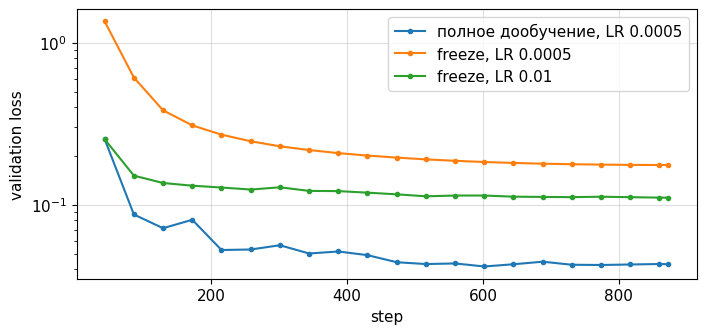

In [33]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'


def n_trainable(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


def run_variant(freeze, lr, out_dir):
    set_seed(SEED)
    m = make_model()
    hist, sec = train_ner(m, tokenized['train'], tokenized['validation'], lr=lr, freeze_encoder=freeze, out_dir=out_dir)
    pred = predict_word_tags(m, val_tokens)
    res = dict(entity_scores(val_gold, pred), token_f1=token_f1(val_gold, pred), train_sec=sec, lr=lr,
               trainable_params=n_trainable(m), peak_mem_mb=TRAIN_PEAK_MEM_MB.get(out_dir),
               final_eval_loss=[h['eval_loss'] for h in hist if 'eval_loss' in h][-1])
    del m
    torch.cuda.empty_cache() if torch.cuda.is_available() else None
    return res, hist


full_eval_losses = [h['eval_loss'] for h in history if 'eval_loss' in h]
ablation = dict(setting=ABLATION, split='validation', epochs=EPOCHS,
                full=dict(scores['validation'], train_sec=RUN_TIMES['train_main_sec'], lr=LR,
                          trainable_params=n_trainable(model), peak_mem_mb=TRAIN_PEAK_MEM_MB.get('runs/main'),
                          final_eval_loss=full_eval_losses[-1]))
ablation['freeze'], hist_freeze = run_variant(True, LR, 'runs/freeze')
FREEZE_HI_LR = 1e-2
ablation['freeze_hi_lr'], hist_freeze_hi = run_variant(True, FREEZE_HI_LR, 'runs/freeze_hi_lr')

print(f'{"":<15}{"F1 micro":>9}{"F1 macro":>9}{"token F1":>9}{"eval loss":>10}{"train, c":>9}{"обучаемых":>12}{"GPU MB":>8}')
for k in ['full', 'freeze', 'freeze_hi_lr']:
    r = ablation[k]
    mem = f'{r["peak_mem_mb"]:>8.0f}' if r['peak_mem_mb'] else f'{"-":>8}'
    print(f'{k:<15}{r["f1_micro"]:>9.4f}{r["f1_macro"]:>9.4f}{r["token_f1"]:>9.4f}{r["final_eval_loss"]:>10.4f}'
          f'{r["train_sec"]:>9.1f}{r["trainable_params"]:>12,}{mem}')

plt.figure(figsize=(8, 3.5))
for name, hist in [(f'полное дообучение, LR {LR:g}', history), (f'freeze, LR {LR:g}', hist_freeze),
                   (f'freeze, LR {FREEZE_HI_LR:g}', hist_freeze_hi)]:
    plt.plot(*zip(*[(h['step'], h['eval_loss']) for h in hist if 'eval_loss' in h]), 'o-', ms=3, label=name)
plt.xlabel('step')
plt.ylabel('validation loss')
plt.yscale('log')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:**

Абляция `freeze` на validation:

| вариант | F1 | обучение | обучаемых параметров | пик памяти GPU |
|---|---|---|---|---|
| полное дообучение (LR 5e-4) | 0.932 | 40.6 с | 29 098 303 | 706 MB |
| только голова, тот же LR | 0.682 | 45.0 с | 2 191 | 574 MB |
| только голова, LR 1e-2 | 0.776 | 35.4 с | 2 191 | 426 MB |

F1 падает на 16–25 пунктов, а время почти не меняется. Обратный проход через энкодер не нужен, но прямой остается. У крошечной модели время шага определяют накладные расходы (коллатор, Python, запуски ядер, eval каждые 43 шага), и на ноутбучной GPU замеры шумят на ±5 с. Память меньше, потому что нет градиентов и состояний Adam для 29M параметров.

Почему замороженный энкодер так плох: его признаки обучены под эмбеддинги предложений (приближение LaBSE), и в них тег BIO линейно не отделяется, особенно граница B/I. Даже с большим LR val loss упирается в ~0.11 против 0.043 у полного дообучения: это потолок линейной головы, а не нехватка шагов.

Чтобы вывод был надежнее, я бы:
- повторил оба варианта на 3–5 сидах и посмотрел разброс;
- отдельно подобрал LR и число эпох для замороженного варианта;
- попробовал MLP-голову или признаки нескольких слоев;
- для полноты сделал вторую абляцию (`all_subwords`).

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:**

Дообученный за 41 секунду `rubert-tiny2` (29M параметров) дает на test F1 по сущностям 0.930 (macro 0.928, токенный F1 0.956). Для сравнения, словарный бейзлайн на validation дает 0.562, а энкодер со случайной головой 0.038.

Главное, что сработало, - полное дообучение с подобранным LR: 5e-4 вместо 2e-4 из шаблона дает +0.3 пункта, а 2e-3 и 4e-3 заметно хуже. Без дообучения энкодера (только голова) F1 всего 0.68–0.78.

Что почти ничего не дало:
- порог уверенности спана: +0.4–0.5 пункта (6.5);
- int8 и fp16 для такой маленькой модели: ускорение 1.33× на CPU и 0.98× на GPU (6.4).

Главные ограничения:
- **ORG** (F1 0.866): ошибки границ на длинных названиях и непоследовательные кавычки в разметке;
- **разметка** местами спорная («Кремль» как LOC);
- **модель** маленькая, всего 3 слоя;
- **домен** один (новости): в нижнем и верхнем регистре или в транслите F1 падает до 0.07–0.12 (6.3);
- **эксперименты:** один сид, а validation использован и для выбора LR.



### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [34]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "RCC-MSU/collection3", "classes": ["LOC", "ORG", "PER"], "n_train": 9301, "n_val": 2153, "n_test": 1922, "params_total": 29098303, "ablation": {"setting": "freeze", "split": "validation", "epochs": 3, "full": {"f1_micro": 0.9316740457101831, "f1_macro": 0.9296037154523557, "precision": 0.9181603773584905, "recall": 0.9455914500850133, "token_f1": 0.9539239814055236, "train_sec": 40.565674699959345, "lr": 0.0005, "trainable_params": 29098303, "peak_mem_mb": 705.83203125, "fi
final F1 micro 0.9303


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [35]:
bonus = {}
if '6.1' in BONUS_TASKS:
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:**


## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [36]:
if '6.2' in BONUS_TASKS:
    ALT_MODEL_ID = 'google-bert/bert-base-multilingual-cased'
    ALT_REVISION = '3f076fdb1ab68d5b2880cb87a0886f315b8146f8'
    ALT_LR = 3e-5
    alt_tok = AutoTokenizer.from_pretrained(ALT_MODEL_ID, revision=ALT_REVISION)
    assert alt_tok.is_fast
    alt_tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                             fn_kwargs=dict(tok=alt_tok))
    set_seed(SEED)
    alt_model = make_model(ALT_MODEL_ID, ALT_REVISION)
    alt_hist, alt_sec = train_ner(alt_model, alt_tokenized['train'], alt_tokenized['validation'], lr=ALT_LR,
                                  tok=alt_tok, out_dir='runs/alt')

    def timed_predict(m, tok, tokens):
        predict_word_tags(m, tokens[:64], tok=tok)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        pred = predict_word_tags(m, tokens, tok=tok)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        return pred, time.perf_counter() - t0

    def fertility(tok, tokens):
        enc_f = tok(tokens, is_split_into_words=True)
        return sum(len(ids) - 2 for ids in enc_f['input_ids']) / sum(map(len, tokens))

    compare = {}
    for name, m, tok, lr, sec, out_dir in [(MODEL_ID, model, tokenizer, LR, RUN_TIMES['train_main_sec'], 'runs/main'),
                                           (ALT_MODEL_ID, alt_model, alt_tok, ALT_LR, alt_sec, 'runs/alt')]:
        vp, v_sec = timed_predict(m, tok, val_tokens)
        tp = predict_word_tags(m, test_tokens, tok=tok)
        n_par = sum(p.numel() for p in m.parameters())
        compare[name] = dict(val_f1=entity_scores(val_gold, vp)['f1_micro'], val_f1_macro=entity_scores(val_gold, vp)['f1_macro'],
                             test_f1=entity_scores(test_gold, tp)['f1_micro'], test_f1_macro=entity_scores(test_gold, tp)['f1_macro'],
                             train_sec=sec, infer_val_sec=v_sec, params=n_par, size_mb_fp32=n_par * 4 / 2**20,
                             peak_train_mem_mb=TRAIN_PEAK_MEM_MB.get(out_dir), lr=lr,
                             subwords_per_word=fertility(tok, val_tokens), vocab=tok.vocab_size)
        per_type = classification_report(test_gold, tp, output_dict=True, zero_division=0)
        compare[name]['test_per_type_f1'] = {t: per_type[t]['f1-score'] for t in ENTITY_TYPES}
    bonus['6.2'] = compare

    keys = ['val_f1', 'test_f1', 'test_f1_macro', 'train_sec', 'infer_val_sec', 'params', 'size_mb_fp32',
            'peak_train_mem_mb', 'subwords_per_word', 'vocab']
    print(f'{"":<20}' + ''.join(f'{n.split("/")[-1]:>34}' for n in compare))
    for k in keys:
        print(f'{k:<20}' + ''.join(f'{compare[n][k]:>34,.4f}' if isinstance(compare[n][k], float) and compare[n][k] < 10
                                   else f'{compare[n][k]:>34,.0f}' for n in compare))
    for n in compare:
        print(n, 'test F1 по типам:', {t: round(float(v), 4) for t, v in compare[n]['test_per_type_f1'].items()})
    del alt_model
    torch.cuda.empty_cache() if torch.cuda.is_available() else None

Map:   0%|          | 0/9301 [00:00<?, ? examples/s]

Map:  22%|██▏       | 2000/9301 [00:00<00:00, 11943.92 examples/s]

Map:  43%|████▎     | 4000/9301 [00:00<00:00, 10825.96 examples/s]

Map:  65%|██████▍   | 6000/9301 [00:00<00:00, 10368.66 examples/s]

Map:  86%|████████▌ | 8000/9301 [00:00<00:00, 10014.22 examples/s]

Map: 100%|██████████| 9301/9301 [00:00<00:00, 9169.64 examples/s] 

... (10 outputs left out)

Loading weights:  44%|████▍     | 87/197 [00:00<00:00, 275.83it/s]

Loading weights:  58%|█████▊    | 115/197 [00:00<00:00, 223.22it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 387.45it/s]

                                          rubert-tiny2      bert-base-multilingual-cased
val_f1                                          0.9317                            0.9692
test_f1                                         0.9303                            0.9651
test_f1_macro                                   0.9281                            0.9634
train_sec                                           41                               328
infer_val_sec                                   1.8446                            5.0348
params                                      29,098,303                       177,268,231
size_mb_fp32                                       111                               676
peak_train_mem_mb                                  706                             3,974
subwords_per_word                               1.1416                            1.7422
vocab                                           83,828                           119,547
cointegrated/rubert-t

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:**

Многоязычный mBERT лучше по всем типам:

| | rubert-tiny2 | mBERT |
|---|---|---|
| F1 validation | 0.932 | 0.969 |
| F1 test | 0.930 | 0.965 |
| F1 macro test | 0.928 | 0.963 |
| ORG / PER / LOC (test) | 0.866 / 0.966 / 0.952 | 0.927 / 0.990 / 0.974 |
| обучение | 41 с | 328 с (8×) |
| инференс validation | 1.8 с | 5.0 с (2.7×) |
| параметров | 29.1M | 177.3M (6×) |
| веса fp32 | 111 MB | 676 MB |
| пик памяти при обучении | 706 MB | 3974 MB (5.6×) |
| сабвордов на слово | 1.14 | 1.74 |

Больше всего mBERT выигрывает на ORG. Он режет русские слова мельче, так что последовательности у него длиннее.

**Честность сравнения.** Одинаковы данные (весь train, оценка на всех validation и test), 3 эпохи, batch 32, warmup 10%, weight decay, fp16, seed 0, `MAX_LENGTH = 128`, а также оценка по словам через `predict_word_tags` и seqeval. Время инференса замерено на одной GPU с прогревом. Различается LR: для tiny он подобран сеткой (5e-4), mBERT взят со стандартным 3e-5 без подбора. Если перекос и есть, то он в пользу tiny, так что преимущество mBERT скорее занижено. Сид один.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [37]:
if '6.3' in BONUS_TASKS:
    CYR = 'абвгдеёжзийклмнопрстуфхцчшщъыьэюя'
    LAT = ['a', 'b', 'v', 'g', 'd', 'e', 'e', 'zh', 'z', 'i', 'y', 'k', 'l', 'm', 'n', 'o', 'p', 'r', 's', 't', 'u', 'f',
           'kh', 'ts', 'ch', 'sh', 'shch', '', 'y', '', 'e', 'yu', 'ya']
    TRANSLIT = dict(zip(CYR, LAT)) | {c.upper(): l.capitalize() for c, l in zip(CYR, LAT)}

    def translit(w):
        return ''.join(TRANSLIT.get(ch, ch) for ch in w) or w

    def make_typo(w, rng):
        if len(w) < 4 or not w.isalpha():
            return w
        i = rng.randrange(1, len(w) - 1)
        op = rng.choice(['swap', 'drop', 'double', 'replace'])
        if op == 'swap':
            return w[:i] + w[i + 1] + w[i] + w[i + 2:]
        if op == 'drop':
            return w[:i] + w[i + 1:]
        if op == 'double':
            return w[:i] + w[i] + w[i:]
        alphabet = CYR if w[i].lower() in CYR else 'abcdefghijklmnopqrstuvwxyz'
        c = rng.choice(alphabet)
        return w[:i] + (c.upper() if w[i].isupper() else c) + w[i + 1:]

    def corrupt(tokens_list, fn, p=1.0, seed=SEED):
        rng = random.Random(seed)
        return [[fn(w, rng) if rng.random() < p else w for w in ws] for ws in tokens_list]

    corruptions = {
        'clean': val_tokens,
        'lower': corrupt(val_tokens, lambda w, r: w.lower()),
        'upper': corrupt(val_tokens, lambda w, r: w.upper()),
        'typos 20% слов': corrupt(val_tokens, make_typo, p=0.2),
        'typos 50% слов': corrupt(val_tokens, make_typo, p=0.5),
        'translit': corrupt(val_tokens, lambda w, r: translit(w)),
    }
    shift = {}
    for name, toks in corruptions.items():
        pred = predict_word_tags(model, toks)
        rep = classification_report(val_gold, pred, output_dict=True, zero_division=0)
        shift[name] = dict(entity_scores(val_gold, pred), per_type={t: rep[t]['f1-score'] for t in ENTITY_TYPES},
                           majority_f1=entity_scores(val_gold, [predict_majority(majority, ws) for ws in toks])['f1_micro'],
                           subwords_per_word=sum(len(ids) - 2 for ids in tokenizer(toks, is_split_into_words=True)['input_ids'])
                           / sum(map(len, toks)))
    bonus['6.3'] = shift
    print('пример:', ' | '.join(f'{n}: {" ".join(t[1][:6])}' for n, t in corruptions.items()))
    print(f'{"":<16}{"F1":>8}{"P":>8}{"R":>8}' + ''.join(f'{t:>8}' for t in ENTITY_TYPES) + f'{"словарь":>9}{"сабв/слово":>11}')
    for name, r in shift.items():
        print(f'{name:<16}{r["f1_micro"]:>8.4f}{r["precision"]:>8.4f}{r["recall"]:>8.4f}'
              + ''.join(f'{r["per_type"][t]:>8.4f}' for t in ENTITY_TYPES) + f'{r["majority_f1"]:>9.4f}{r["subwords_per_word"]:>11.2f}')

пример: clean: Президент США Барак Обама в пятницу | lower: президент сша барак обама в пятницу | upper: ПРЕЗИДЕНТ США БАРАК ОБАМА В ПЯТНИЦУ | typos 20% слов: Президент США Барак Обама в пятницу | typos 50% слов: Преезидент США Баак Обаам в пятницу | translit: Prezident SShA Barak Obama v pyatnitsu
                      F1       P       R     LOC     ORG     PER  словарь сабв/слово
clean             0.9317  0.9182  0.9456  0.9528  0.8623  0.9737   0.5615       1.14
lower             0.1241  0.4265  0.0726  0.0683  0.0778  0.1891   0.0039       1.23
upper             0.0681  0.0430  0.1635  0.1339  0.0559  0.0183   0.2339       3.46
typos 20% слов    0.8803  0.8585  0.9033  0.9004  0.8136  0.9201   0.4828       1.34
typos 50% слов    0.7931  0.7635  0.8251  0.8024  0.7484  0.8202   0.3730       1.64
translit          0.1033  0.0693  0.2026  0.0000  0.0833  0.1691   0.0679       2.47


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:**

Устойчивость к порче validation (метки не меняются):

| порча | F1 | P | R | словарь F1 | сабвордов на слово |
|---|---|---|---|---|---|
| без порчи | 0.932 | | | 0.562 | 1.14 |
| нижний регистр | 0.124 | 0.43 | 0.07 | 0.004 | |
| верхний регистр | 0.068 | 0.04 | | 0.234 | 3.46 |
| транслит | 0.103 | | | | 2.47 |
| опечатки в 20% слов | 0.880 | | | | 1.34 |
| опечатки в 50% слов | 0.793 | | | | 1.64 |

Сильнее всего роняют F1 смена регистра и транслит. В русских новостях заглавная буква - главный признак имени собственного, а словарь модели регистрозависимый:
- **Нижний регистр.** Модель почти перестает находить сущности (R 0.07): нет заглавной буквы - нет сущности.
- **Верхний регистр.** Каждое слово выглядит как аббревиатура вроде МВД или РФ и режется в 3.46 сабворда вместо 1.14. Получается масса ложных спанов (P 0.04). Словарный бейзлайн тут держит 0.234: аббревиатуры в верхнем регистре не меняются.
- **Транслит.** Латиница в train - это в основном названия организаций (Bloomberg, Apple), а слова режутся в 2.47 сабворда. LOC не находится ни одного (F1 0.000).
- **Опечатки** мягче. Портятся сабворды только испорченных слов, а регистр и контекст сохраняются.

Лечится это аугментацией регистра при обучении (случайно приводить предложения к нижнему или верхнему регистру) или отдельной моделью под нужный домен.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [38]:
if '6.4' in BONUS_TASKS:
    import io
    import warnings

    def bench(m, batch, dev, n_runs=20, n_warmup=5):
        m = m.eval().to(dev)
        batch = {k: v.to(dev) for k, v in batch.items()}
        with torch.inference_mode():
            for _ in range(n_warmup):
                m(**batch)
            if dev.type == 'cuda':
                torch.cuda.synchronize()
            times = []
            for _ in range(n_runs):
                t0 = time.perf_counter()
                m(**batch)
                if dev.type == 'cuda':
                    torch.cuda.synchronize()
                times.append(time.perf_counter() - t0)
        return 1000 * float(np.mean(times)), 1000 * float(np.std(times))

    def state_mb(m):
        buf = io.BytesIO()
        torch.save(m.state_dict(), buf)
        return buf.tell() / 2**20

    bench_batch = dict(tokenizer(val_tokens[:64], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH,
                                 padding=True, return_tensors='pt'))
    cpu = torch.device('cpu')
    speed = dict(batch=list(bench_batch['input_ids'].shape), cpu_threads=torch.get_num_threads())
    variants = {}

    m_fp32 = copy.deepcopy(model).float().cpu().eval()
    variants['cpu fp32'] = (m_fp32, cpu)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        m_int8 = torch.ao.quantization.quantize_dynamic(copy.deepcopy(m_fp32), {torch.nn.Linear}, dtype=torch.qint8)
    variants['cpu int8 (dynamic)'] = (m_int8, cpu)
    if device.type == 'cuda':
        variants['gpu fp32'] = (copy.deepcopy(model).float(), device)
        variants['gpu fp16'] = (copy.deepcopy(model).half(), device)

    for name, (m, dev) in variants.items():
        ms, sd = bench(m, bench_batch, dev)
        pred = predict_word_tags(m, val_tokens, dev=dev)
        speed[name] = dict(ms=ms, std_ms=sd, val_f1=entity_scores(val_gold, pred)['f1_micro'],
                           agree_with_fp32=float(np.mean([a == b for ps, qs in zip(pred, val_pred) for a, b in zip(ps, qs)])),
                           size_mb=state_mb(m))
        m.cpu()
    for base_name, fast_name in [('cpu fp32', 'cpu int8 (dynamic)'), ('gpu fp32', 'gpu fp16')]:
        if fast_name in speed:
            speed[fast_name]['speedup'] = speed[base_name]['ms'] / speed[fast_name]['ms']
    bonus['6.4'] = speed

    blocks_main = params_by_block(model)
    linear_params = sum(mod.weight.numel() for mod in model.modules() if isinstance(mod, torch.nn.Linear))
    print(f'батч {speed["batch"]}, потоков CPU {speed["cpu_threads"]}; параметров в Linear {linear_params:,} '
          f'из {sum(p.numel() for p in model.parameters()):,}, в эмбеддингах {blocks_main["embeddings"]:,}')
    print(f'{"":<20}{"ms":>9}{"± std":>8}{"speedup":>9}{"val F1":>9}{"теги = fp32":>12}{"MB":>8}')
    for name in variants:
        r = speed[name]
        print(f'{name:<20}{r["ms"]:>9.2f}{r["std_ms"]:>8.2f}{r.get("speedup", 1.0):>9.2f}{r["val_f1"]:>9.4f}'
              f'{r["agree_with_fp32"]:>12.4%}{r["size_mb"]:>8.1f}')
    del variants, m_fp32, m_int8

батч [64, 58], потоков CPU 6; параметров в Linear 2,293,512 из 29,098,303, в эмбеддингах 26,794,560
                           ms   ± std  speedup   val F1 теги = fp32      MB
cpu fp32               132.61    7.60     1.00   0.9317   100.0000%   111.0
cpu int8 (dynamic)      99.99   13.33     1.33   0.9319    99.9270%   104.5
gpu fp32                 7.73    0.08     1.00   0.9317   100.0000%   111.0
gpu fp16                 7.87    0.08     0.98   0.9317   100.0000%    55.5


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:**

Батч 64 предложения × 58 сабвордов, 5 прогревов и среднее по 20 запускам:

| вариант | задержка | F1 validation | теги совпадают с fp32 | размер весов |
|---|---|---|---|---|
| CPU fp32 (6 потоков) | 132.6 ± 7.6 мс | 0.9317 | 100% | 111 MB |
| CPU int8, динамическая квантизация Linear | 100.0 ± 13.3 мс (1.33×) | 0.9319 | 99.93% | 104.5 MB |
| GPU fp32 (RTX 3060) | 7.73 мс | 0.9317 | 100% | 111 MB |
| GPU fp16 | 7.87 мс (0.98×, выигрыша нет) | 0.9317 | 100% | 55.5 MB |

Метрика не изменилась.

Выигрыш маленький из-за устройства модели. У `rubert-tiny2` 92% параметров (26.8M) - это эмбеддинги, а динамическая квантизация трогает только Linear (2.3M параметров). Поиск по таблице эмбеддингов вычислений не требует, поэтому размер почти не уменьшился. Вычислений в трех слоях с hidden 312 мало, так что заметную часть времени занимают softmax, LayerNorm и GELU во fp32, квантование и деквантование активаций и накладные расходы Python. На GPU такой батч слишком мал: время определяют запуски ядер, а не арифметика, поэтому fp16 только вдвое уменьшает размер весов. У base-моделей (12 слоев × 768) основная доля вычислений приходится на матричные умножения в слоях, и там int8 и fp16 должны давать кратный выигрыш. Здесь я это не проверял.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

mean  лучший порог 0.750: F1 0.9360 (порог 0: 0.9317, +0.0043), P 0.9344, R 0.9376 | test: 0.9303 -> 0.9344
min   лучший порог 0.750: F1 0.9368 (порог 0: 0.9317, +0.0052), P 0.9442, R 0.9296 | test: 0.9303 -> 0.9369
средняя уверенность спана: верные 0.987, ошибочные 0.857 (3893 / 347 спанов)


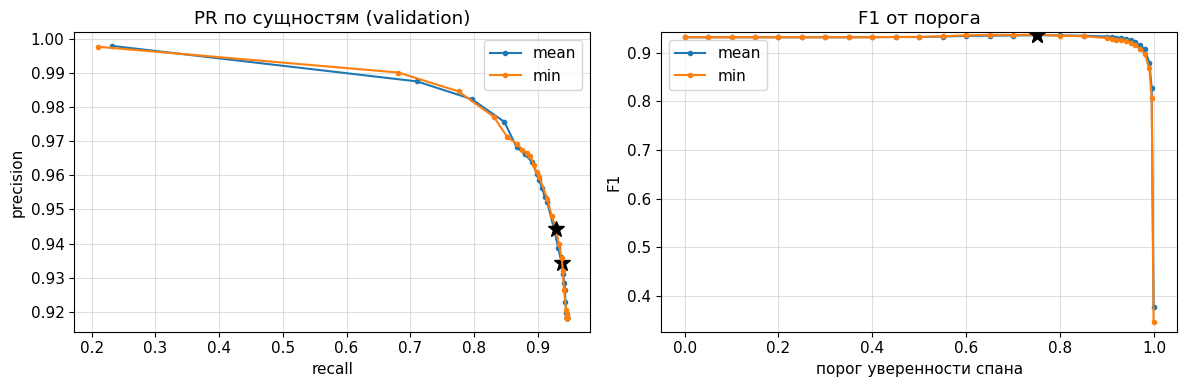

In [39]:
if '6.5' in BONUS_TASKS:
    def spans_with_conf(tags_list, probs_list):
        out = []
        for k, (tags, probs) in enumerate(zip(tags_list, probs_list)):
            for s, e, t in bio_to_spans(tags):
                out.append((k, (s, e, t), float(np.mean(probs[s:e])), float(np.min(probs[s:e]))))
        return out

    def pr_at(items, gold_sets, thr, agg):
        kept = [(k, sp) for k, sp, mean_c, min_c in items if (mean_c if agg == 'mean' else min_c) >= thr]
        tp = sum(sp in gold_sets[k] for k, sp in kept)
        n_gold = sum(map(len, gold_sets))
        p = tp / len(kept) if kept else 1.0
        r = tp / n_gold
        return p, r, (2 * p * r / (p + r) if tp else 0.0)

    vp, vprob = predict_word_tags(model, val_tokens, return_probs=True)
    assert vp == val_pred
    items = spans_with_conf(vp, vprob)
    gold_sets = [set(s) for s in val_gold_spans]
    thresholds = np.unique(np.concatenate([np.arange(0, 0.9, 0.05), np.arange(0.9, 1.0, 0.01), [0.995, 0.999]])).round(3)
    curves = {agg: [pr_at(items, gold_sets, thr, agg) for thr in thresholds] for agg in ['mean', 'min']}

    assert abs(curves['mean'][0][2] - entity_scores(val_gold, val_pred)['f1_micro']) < 1e-9

    thr_res = {}
    for agg, curve in curves.items():
        best = int(np.argmax([f for _, _, f in curve]))
        thr_res[agg] = dict(best_thr=float(thresholds[best]), best_f1=curve[best][2], f1_at_0=curve[0][2],
                            p_at_best=curve[best][0], r_at_best=curve[best][1])

    tpred, tprob = predict_word_tags(model, test_tokens, return_probs=True)
    test_items = spans_with_conf(tpred, tprob)
    test_gold_sets = [set(bio_to_spans(t)) for t in test_gold]
    for agg in curves:
        thr_res[agg]['test_f1_at_0'] = pr_at(test_items, test_gold_sets, 0.0, agg)[2]
        thr_res[agg]['test_f1_at_best_val_thr'] = pr_at(test_items, test_gold_sets, thr_res[agg]['best_thr'], agg)[2]
    correct_conf = [mn for k, sp, mn, _ in items if sp in gold_sets[k]]
    wrong_conf = [mn for k, sp, mn, _ in items if sp not in gold_sets[k]]
    thr_res['mean_conf_correct'], thr_res['mean_conf_wrong'] = float(np.mean(correct_conf)), float(np.mean(wrong_conf))
    bonus['6.5'] = thr_res

    for agg in curves:
        r = thr_res[agg]
        print(f'{agg:<5} лучший порог {r["best_thr"]:.3f}: F1 {r["best_f1"]:.4f} (порог 0: {r["f1_at_0"]:.4f}, '
              f'+{r["best_f1"] - r["f1_at_0"]:.4f}), P {r["p_at_best"]:.4f}, R {r["r_at_best"]:.4f} | test: '
              f'{r["test_f1_at_0"]:.4f} -> {r["test_f1_at_best_val_thr"]:.4f}')
    print(f'средняя уверенность спана: верные {thr_res["mean_conf_correct"]:.3f}, ошибочные {thr_res["mean_conf_wrong"]:.3f} '
          f'({len(correct_conf)} / {len(wrong_conf)} спанов)')

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for agg, curve in curves.items():
        p, r, f = map(np.array, zip(*curve))
        axes[0].plot(r, p, 'o-', ms=3, label=agg)
        axes[1].plot(thresholds, f, 'o-', ms=3, label=agg)
        b = int(np.argmax(f))
        axes[0].plot(r[b], p[b], 'k*', ms=12)
        axes[1].plot(thresholds[b], f[b], 'k*', ms=12)
    axes[0].set(xlabel='recall', ylabel='precision', title='PR по сущностям (validation)')
    axes[1].set(xlabel='порог уверенности спана', ylabel='F1', title='F1 от порога', ylim=(min(f) - 0.02, max(f) + 0.005))
    for ax in axes:
        ax.grid(True, alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:**

Лучший порог на validation для обоих вариантов уверенности - 0.75:

| уверенность | F1 (порог 0 → 0.75) | P | R | test F1 (порог 0 → 0.75) |
|---|---|---|---|---|
| средняя | 0.9317 → 0.9360 (+0.43 пункта) | 0.934 | 0.938 | 0.930 → 0.934 |
| минимальная | 0.9317 → 0.9368 (+0.52 пункта) | 0.944 | 0.930 | 0.930 → 0.937 |

Порог переносится на test. Выигрыш маленький, потому что модель и так уверена: средняя уверенность верных спанов 0.987, ошибочных 0.857.

Минимальная уверенность строже средней: одно сомнительное слово (часто крайнее) отбрасывает весь спан. Поэтому она лучше отсекает ошибки границ и дает больший precision при меньшем recall. Средняя сглаживает одно слабое слово, если остальные уверенные.

Порог не может поднять recall, потому что он только удаляет предсказанные спаны. Recall = TP / (число истинных), и удалением TP не прибавить. Потолок - recall при пороге 0 (0.946). Чтобы поднять recall, нужно менять само декодирование ,например, понижать требуемую вероятность не-O тегов.

In [40]:
(ARTIFACTS / 'bonus_metrics.json').write_text(
    json.dumps(json_ready(dict(bonus_tasks=sorted(BONUS_TASKS), fast_mode=FAST_MODE, **bonus)), ensure_ascii=False, indent=2),
    encoding='utf-8')
print('saved', ARTIFACTS / 'bonus_metrics.json', sorted(bonus))

saved artifacts\bonus_metrics.json ['6.2', '6.3', '6.4', '6.5']
